# Evaluate a Trade Space

This is the first of eight notebooks on trade studies with the `tatc.tradespace` module (installed with `pip install tatc[tradespace]`). Together they follow one trade from start to finish, and each adds one idea to the notebooks before it.

The trade is that of a pre-Phase A study of an imaging constellation: **how many satellites, in how many orbit planes, observe the Earth often enough?** Each orbit plane needs its own launch, so fewer planes cost less. A point on the Earth is **sufficiently sampled** if it is observed at least four times a day.

This notebook takes the four steps of every trade study:

1. declare the **design space**: the decisions and their options;
2. define the **study**: how each design is built and evaluated;
3. **evaluate** the designs;
4. find the **Pareto-efficient** designs, and plot the trade.

## Configure the Analysis

Each design is analyzed over one day, at 100 points on the Earth, and may have at most 10 satellites.

In [1]:
from datetime import datetime, timedelta, timezone

import matplotlib.pyplot as plt

START = datetime(2026, 7, 1, tzinfo=timezone.utc)
DURATION = timedelta(days=1)  # the period of the analysis
N_POINTS = 100  # points sampled in each replicate
N_REPLICATES = 5  # replicates (samples of points) of each design
SAMPLES_PER_DAY = 4  # observations a day of a sufficiently sampled point
MAX_SATELLITES = 10

## Declare the Design Space

A `DesignSpace` names each decision and its options. Every design here has:

* an **altitude**: 500 to 800 km, in steps of 100 km (`Real`);
* an imager's **field of regard**: 30 or 60 degrees (`Categorical`);
* a **layout** of its orbits, one of two alternatives (a `Choice`):
  * a **Walker** constellation (`walker_space`): an inclination, a number of planes, a number of satellites in each plane, and the phasing of the satellites between planes; or
  * one or two **sun-synchronous** planes (`sso_planes_space`), each with an equator crossing time and one or two satellites.

Each alternative has its own decisions: only Walker designs have an inclination. A constraint limits a design to 10 satellites. It returns the number of satellites over the limit, and a design is feasible if that number is zero or less.

The last entry, `points_seed`, is not a decision. It is an `Uncertain` parameter, which the next section explains.

In [2]:
from tatc.tradespace import (
    Categorical,
    Choice,
    DesignSpace,
    Integer,
    Real,
    Uncertain,
    count_satellites,
    sso_planes_space,
    walker_space,
)

space = DesignSpace(
    altitude=Real(500e3, 800e3, step=100e3),
    field_of_regard=Categorical([30, 60]),
    layout=Choice(
        walker=walker_space(
            inclination=Real(45, 75, step=15),
            planes=Integer(1, 4),
            per_plane=Integer(1, 4),
        ),
        sso=sso_planes_space(
            crossing=Real(6, 18, step=3),
            satellites=Integer(1, 2),
            count=Integer(1, 2),
        ),
    ),
    points_seed=Uncertain.seed(),
    constraints=[lambda d: count_satellites(d.layout) - MAX_SATELLITES],
)
designs = space.enumerate()
print(f"{len(designs)} feasible designs")

1096 feasible designs


## Define the Study

A study evaluates each design in three steps:

1. **build** its satellites: an imager in each orbit of its layout (`build`, with `build_constellation`);
2. **observe** points on the Earth for a day (`Observations` of `Targets`);
3. **measure** the observations: the share of points observed at least four times (`count_samples`).

The points are a random sample of the Earth, so a share is an estimate, with sampling error. The study therefore evaluates each design five times, in five **replicates**. Each replicate draws its own sample of points from the uncertain `points_seed`, and every design sees the same five samples, so that differences between designs are not differences between their samples. The points of a sample are a lattice in a random orientation (`generate_points_rotated_lattice`), which covers the Earth evenly.

`ObservationStudy` combines the three steps. Its other arguments:

* `layout` names the decision whose satellites and planes the study counts;
* `n_jobs=-1` evaluates designs in parallel, on every processor;
* the `directory` of the `Observations` caches the observations of each satellite on disk, as many designs share satellites;
* `store` keeps the results in a file: running the notebook again reads them rather than evaluating the designs again (unless the study changes).

In [3]:
import tempfile
from pathlib import Path

from tatc.generation import generate_points_rotated_lattice
from tatc.schemas import Instrument
from tatc.tradespace import ObservationStudy, Observations, ResultStore, Targets, build_constellation


def build(d):
    """The satellites of a design: an imager in each orbit of its layout."""
    imager = Instrument(name="imager", field_of_regard=d.field_of_regard)
    return build_constellation(d.layout, imager, epoch=START, altitude=d.altitude)


def count_samples(observations, duration=DURATION):
    """The share (%) of points observed at least SAMPLES_PER_DAY times a day."""
    if len(observations) == 0:  # no satellites
        return {"sufficient": 0.0}
    samples = observations.groupby("target_hash").size()
    threshold = SAMPLES_PER_DAY * duration / timedelta(days=1)
    return {"sufficient": 100 * (samples >= threshold).sum() / N_POINTS}


CACHE_DIRECTORY = Path(tempfile.gettempdir()) / "tatc-trade-space"
# the points of each replicate: a lattice in a random orientation, from its seed
TARGETS = Targets(generate_points_rotated_lattice, N_POINTS, seed="points_seed")
OBSERVATIONS = Observations(TARGETS, START, DURATION, directory=CACHE_DIRECTORY)

study = ObservationStudy(
    space,
    build,
    OBSERVATIONS,
    count_samples,
    layout="layout",
    replicates=N_REPLICATES,
    n_jobs=-1,
    store=ResultStore(CACHE_DIRECTORY / "results.sqlite"),
)

## Evaluate Every Design

The design space is small enough to evaluate every design: 1,096 designs in five replicates each, which takes a few minutes the first time. `study.run` gives a row per evaluation (a design in a replicate), with the design's values and its metrics. The rows of the last design show how its share differs between its five samples of points:

In [4]:
results = study.run(designs)
print(f"{len(results)} evaluations: {len(designs)} designs x {N_REPLICATES} replicates")
results[["design", "replicate", "altitude", "field_of_regard", "layout", "satellites", "planes", "sufficient"]].tail()

5480 evaluations: 1096 designs x 5 replicates


,design,replicate,altitude,field_of_regard,layout,satellites,planes,sufficient
5475,29287797ce8d,0,800000.0,60,sso,4,2,56.0
5476,29287797ce8d,1,800000.0,60,sso,4,2,52.0
5477,29287797ce8d,2,800000.0,60,sso,4,2,53.0
5478,29287797ce8d,3,800000.0,60,sso,4,2,50.0
5479,29287797ce8d,4,800000.0,60,sso,4,2,58.0


## Find the Efficient Designs

`summarize` averages the replicates of each design: a row per design, with the mean of each metric and its standard error (`se`, the uncertainty of the mean).

The objectives are fewer satellites, fewer planes, and more points sufficiently sampled. A design is **Pareto-efficient** if no other design is as good in every objective and better in one. `pareto_front` finds the efficient designs, given whether each objective is minimized or maximized. (`describe`, from the module `trade_space_example.py` beside the notebooks, describes each design in a few words.)

In [5]:
from trade_space_example import describe
from tatc.tradespace import pareto_front, summarize

OBJECTIVES = {"satellites": "min", "planes": "min", "sufficient": "max"}
summary = summarize(results, list(OBJECTIVES))
summary["pareto"] = pareto_front(summary, OBJECTIVES)
summary["description"] = summary.apply(describe, axis=1)
front = summary[summary.pareto].sort_values(["satellites", "planes"])
front[["description", "satellites", "planes", "sufficient", "sufficient se"]].round(1)

,description,satellites,planes,sufficient,sufficient se
1054,"800 km, 60 deg FOR, SSO: 1 at 18:00",1.0,1.0,3.2,0.9
960,"800 km, 60 deg FOR, Walker 45 deg: 1 x 2 (spac...",2.0,1.0,16.6,1.2
963,"800 km, 60 deg FOR, Walker 45 deg: 2 x 1 (spac...",2.0,2.0,30.2,2.2
961,"800 km, 60 deg FOR, Walker 45 deg: 1 x 3 (spac...",3.0,1.0,38.0,1.2
962,"800 km, 60 deg FOR, Walker 45 deg: 1 x 4 (spac...",4.0,1.0,68.2,1.8
965,"800 km, 60 deg FOR, Walker 45 deg: 2 x 2 (spac...",4.0,2.0,69.6,0.8
1025,"800 km, 60 deg FOR, Walker 75 deg: 2 x 3 (spac...",6.0,2.0,97.8,0.2


## Plot the Trade

`plot_designs` plots every design by two metrics, colored by a third, with the efficient designs ringed:

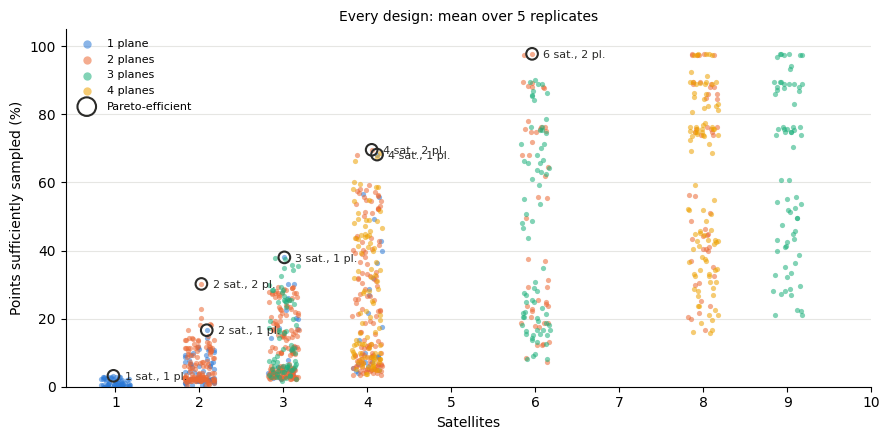

In [6]:
from trade_space_example import planes_name
from tatc.tradespace import plot_designs

ax = plot_designs(
    summary,
    "satellites",
    "sufficient",
    by="planes",
    front="pareto",
    labels=lambda row: f"{row.satellites:.0f} sat., {row.planes:.0f} pl.",
    names=planes_name,
    jitter=0.18,  # spreads the designs of each number of satellites, for legibility
    legend="upper left",
)
ax.set(
    xlabel="Satellites", ylabel="Points sufficiently sampled (%)", xticks=range(1, MAX_SATELLITES + 1), ylim=(0, 105)
)
ax.set_title("Every design: mean over 5 replicates", fontsize=10)
ax.figure.tight_layout()
plt.show()

Seven of the 1,096 designs are efficient. All of them fly at 800 km with the wider field of regard (60 degrees), which observe the most points per satellite, so the trade is in the numbers of satellites and planes:

* one satellite samples only 3% of the points sufficiently;
* two satellites in two planes sample 30%, nearly twice as many as two in one plane (17%);
* four satellites sample about two thirds of the points, in one plane or two (68% and 70%);
* six satellites in two planes sample 98%, and no design of more satellites is efficient.

Designs with the same number of satellites differ widely (the vertical spread in the figure): their layout matters as much as their number.

## Summary

* A `DesignSpace` declares the decisions of a trade, with choices between alternatives (`Choice`), constraints, and uncertain parameters (`Uncertain`) drawn for each replicate.
* An `ObservationStudy` builds, observes, and measures each design in replicates, in parallel, with a cache of observations and a store of results.
* `summarize` averages the replicates of each design, and `pareto_front` and `plot_designs` find and show the efficient designs.

The next notebook, `ExplainTradeSpace`, measures sampling by its purpose and explains why designs differ. The notebooks after it search larger spaces (`SearchTradeSpace`), rank designs with the uncertainty of their replicates (`RankUncertainDesigns`), compare them across scenarios (`CompareScenarios`), trade their cost and utility (`TradeCostAndUtility`), and plan their deployment (`PlanDeployment`) and failures (`PlanForFailures`).

## Notes

* `trade_space_example.py` repeats the design space and study of this notebook, and the parts of later notebooks that the notebooks after them use, so that each notebook can import them.
* The building blocks of the layouts declare more than this notebook needs to say: the phasing of a Walker constellation depends on its number of planes, and sun-synchronous planes are unordered and must cross the equator at different times. See `walker_space` and `sso_planes_space`.